In [1]:
galaxy_cluster_A2029 = gal_df[(gal_df['rvz_redshift'] >0.06 )& (gal_df['rvz_redshift'] <0.0925)]
galaxy_cluster_A2029['rvz_redshift'].hist(bins=100)
plt.xlabel('Redshift')
plt.ylabel('Number of galaxies')
plt.show()
galaxy_cluster_A2029['rvz_radvel'].hist(bins=100)
plt.xlabel('Radial Velocity (km/s)')
plt.ylabel('Number of galaxies')
plt.show

num_bins = 600
velocities = galaxy_cluster_A2029['rvz_radvel']
standardised_plot = galaxy_cluster_A2029['rvz_radvel']
standardised_plot.hist(bins=num_bins)
galaxy_num, bin_edges = np.histogram(velocities, bins=num_bins)
bin_centres = 0.5*(bin_edges[:-1] + bin_edges[1:])
height_guess = np.max(galaxy_num)
standarddev_guess = np.std(velocities)
mean_guess = np.mean(velocities)
def gauss(x,a,mu,sigma):
    return 1+a*np.exp(-(x-mu)**2/(2*sigma**2))
params, covar = curve_fit(gauss, bin_centres, galaxy_num, p0=[height_guess, mean_guess, standarddev_guess])
height_2029 = params[0]
mean_2029 = params[1]
standarddev_2029 = params[2]

lower_limit = mean_guess-2*standarddev_guess
upper_limit = mean_guess+2*standarddev_guess

plt.plot(bin_centres, gauss(bin_centres, height_2029, mean_2029, standarddev_2029), label='Gaussian fit')
plt.plot(np.ones(25)*lower_limit,np.arange(0,25),color='r', label = 'Cluster cut off')
plt.plot(np.ones(25)*upper_limit,np.arange(0,25), color='r')
plt.legend()
plt.xlabel('Recessional Velocity (km/s)')
plt.ylabel('Number of Galaxies')
plt.show()

galaxy_cluster_A2029_bg = galaxy_cluster_A2029[(galaxy_cluster_A2029['rvz_radvel'] >upper_limit ) | (galaxy_cluster_A2029['rvz_radvel'] <lower_limit)]
galaxy_cluster_A2029_bg['rvz_radvel'].hist(bins=100)
plt.show()
bg_gal_nums,bg_bin_edge=np.histogram(galaxy_cluster_A2029_bg['rvz_radvel'], bins=600)
background_galaxies = galaxy_num[galaxy_num<=np.max(bg_gal_nums)]
#for i in range (len(galaxy_cluster_A2029['rvz_radvel'])):
 #   if galaxy_num[i] <= np.max(galaxy_cluster_A2029_bg['rvz_radvel']):
  #      background_galaxies.append(standardised_plot[i])
background_level = np.sum(background_galaxies)/(np.max(galaxy_cluster_A2029['rvz_radvel'])-np.min(galaxy_cluster_A2029['rvz_radvel']))
bin_size = (np.max(galaxy_cluster_A2029['rvz_radvel'])-np.min(galaxy_cluster_A2029['rvz_radvel']))*(600**(-1))
print(background_galaxies)
print(len(background_galaxies))
print(np.sum(background_galaxies))
print(np.max(galaxy_cluster_A2029['rvz_radvel'])-np.min(galaxy_cluster_A2029['rvz_radvel']))
print(background_level )
standardised_plot.hist(bins=num_bins)
plt.plot(np.ones(25)*lower_limit,np.arange(0,25),color='r', label = 'Cluster cut off')
plt.plot(np.ones(25)*upper_limit,np.arange(0,25), color='r')
plt.plot(np.arange(np.min(galaxy_cluster_A2029['rvz_radvel']),np.max(galaxy_cluster_A2029['rvz_radvel'])),
         np.ones(int(np.max(galaxy_cluster_A2029['rvz_radvel'])-np.min(galaxy_cluster_A2029['rvz_radvel']))+1)*background_level,color='g'
         , label = 'Background level')
plt.legend()
plt.xlabel('Recessional Velocity (km/s)')
plt.ylabel('Number of Galaxies')
plt.show()

NameError: name 'gal_df' is not defined

[127.19801331 111.29826165  98.93178813  89.03860932  71.23088746
  59.35907288  50.87920533  44.51930466  35.61544373  29.67953644
  25.43960266  22.25965233  19.78635763  17.80772186  16.18883806
  14.83976822]
0.8649464905391936
0.7568281792217945


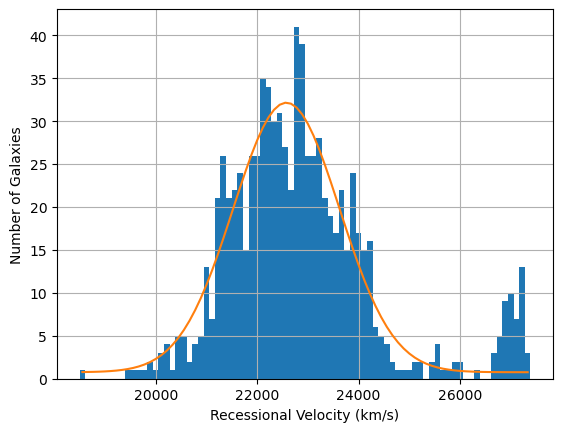

0.6727361593082617
0.6054625433774355
0.4843700347019484
0.40364169558495705
0.3459785962156774


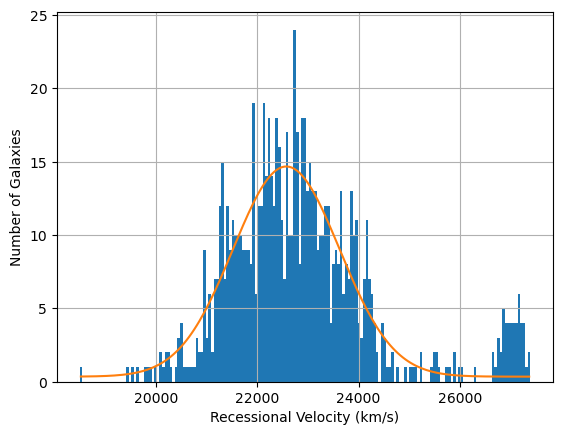

0.3027312716887178
0.2421850173509742
0.20182084779247852
0.1729892981078387
0.1513656358443589


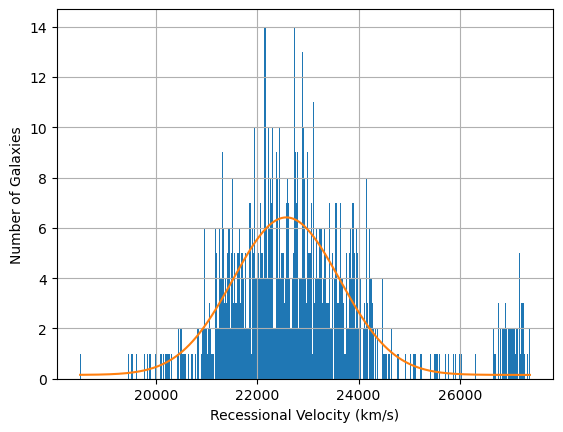

0.13454723186165235
0.1210925086754871
0.11008409879589737
0.10091042389623926
[1050.40982938 1050.88117703 1055.24999348 1053.62006925 1051.68511401
 1051.66910288 1051.98939871 1053.02243047 1053.2228692  1053.24379385
 1053.02264738 1053.05804797 1053.22353396 1052.70585706 1053.05461569
 1053.242926  ]


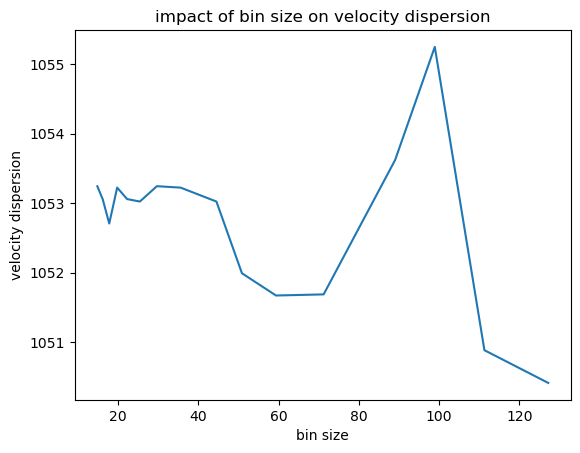

In [7]:
num_bins = [70,80,90,100,125,150,175,200,250,300,350,400,450,500,550,600]
bin_size=np.zeros(len(num_bins))
for i in range (len(num_bins)):
    bin_size[i] = (np.max(galaxy_cluster_A2029['rvz_radvel'])-np.min(galaxy_cluster_A2029['rvz_radvel']))*(num_bins[i]**(-1))
print(bin_size)
bin_error = np.zeros(len(num_bins))
for j in range (len(num_bins)):
    galaxy_num, bin_edges = np.histogram(galaxy_cluster_A2029['rvz_radvel'], bins=num_bins[j])
    bin_centres = 0.5*(bin_edges[:-1] + bin_edges[1:])
    height_guess = np.max(galaxy_num)
    standarddev_guess = np.std(galaxy_cluster_A2029['rvz_radvel'])
    mean_guess = np.mean(galaxy_cluster_A2029['rvz_radvel'])
    bg = 0.0068*bin_size[j]
    print(bg)
    def gauss(x,a,mu,sigma):
        return bg+a*np.exp(-(x-mu)**2/(2*sigma**2))
    params, covar = curve_fit(gauss, bin_centres, galaxy_num, p0=[height_guess, mean_guess, standarddev_guess])
    bin_error[j] = params[2]
    if j%5==1:
        galaxy_cluster_A2029['rvz_radvel'].hist(bins=num_bins[j])
        plt.plot(bin_centres, gauss(bin_centres, params[0],params[1], params[2]))
        plt.xlabel('Recessional Velocity (km/s)')
        plt.ylabel('Number of Galaxies')
        plt.show()
print(bin_error) 
    
error_from_bins_2029 = bin_error.std()
omega_m_bin_variation = bin_error
plt.plot(bin_size,omega_m_bin_variation )
plt.xlabel('bin size')
plt.ylabel('velocity dispersion')
plt.title('impact of bin size on velocity dispersion')
plt.show()

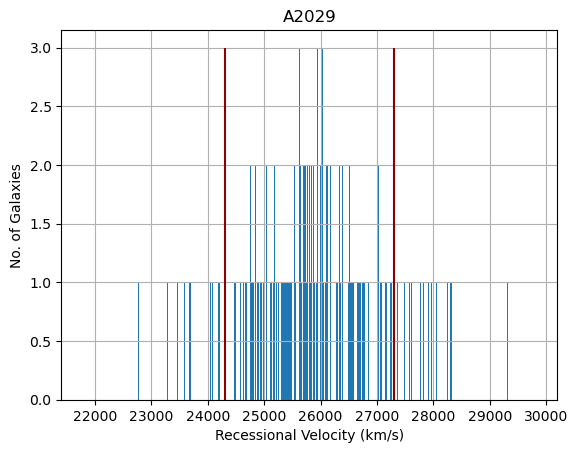

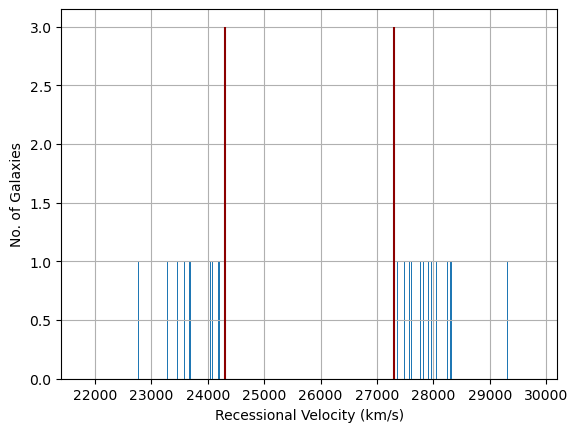

0.025078237956243133


In [48]:
def query(ra, dec, radius_guess):
    result_table = customSimbad.query_region(coord.SkyCoord(ra, dec, unit='deg'), radius=radius_guess)
    df = result_table.to_pandas()
    gal_df = df[df['otype'] == 'G']

    return gal_df
    
radii = [25,24,46,32,34,21]
lower_limit = [0.065,0.072,0.035,0.043,0.06,0.063]
upper_limit = [0.092,0.105,0.1,0.073,0.08,0.09]
background_rate = []
lower_lims = [0.07,0.081,0.046,0.052,0.064,0.070]
upper_lims = [0.081,0.091,0.058,0.064,0.073,0.0795]


for p in range (6):
    # Set up custom query and define which columns we want
    customSimbad = Simbad()
    customSimbad.add_votable_fields('ra', 'dec', 'mesdistance', 'otype', 'rvz_radvel', 'rvz_redshift')
    
    
    # query
    ra_A2029 = XCOP_clusters['ra'][p]
    dec_A2029 = XCOP_clusters['dec'][p]
    radius_A2029 = radii[p] * u.arcmin
    gal_df = query(ra_A2029, dec_A2029, radius_A2029) # Get full query again
    
    # Zoom in and get array
    cluster = gal_df[(gal_df['rvz_redshift']>lower_limit[p])&(gal_df['rvz_redshift']<upper_limit[p])]
    cluster_vels = cluster['rvz_radvel'].values
   # sky = gal_df # 'Whole sky'
    
    #Compute mu and sigma guesses
    mu_guess = np.mean(cluster_vels)
    sigma_guess = np.std(cluster_vels)
    
    nb = 2000 # Number of bins
    
    # Compute histogram values (i.e. x and y)
    v_hist, bin_edges = np.histogram(cluster_vels, bins=nb)
    
    # Compute bin centres
    bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    lower_lim = lower_lims[p]*3e5 #mu_guess-(2*sigma_guess)
    upper_lim = upper_lims[p]*3e5 #mu_guess+(2*sigma_guess)
    sky = gal_df[(gal_df['rvz_redshift']>lower_limit[p])&(gal_df['rvz_redshift']<upper_limit[p])]
    
    #Plot recessional velocity distribution and gaussian 
    sky['rvz_radvel'].hist(bins = nb)
    #plt.plot(bin_centers, gauss_func(bin_centers, a, mu, sigma))
    plt.vlines(lower_lim, 0, v_hist.max(), color = 'darkred')
    plt.vlines(upper_lim, 0, v_hist.max(), color = 'darkred')
    plt.xlabel('Recessional Velocity (km/s)')
    plt.ylabel('No. of Galaxies')
    plt.title('A2029')
    plt.show()
    
    nocluster = sky[(sky['rvz_radvel'] < lower_lim) | (sky['rvz_radvel'] > upper_lim)]
    nocluster['rvz_radvel'].hist(bins=nb)
    plt.vlines(lower_lim, 0, v_hist.max(), color = 'darkred')
    plt.vlines(upper_lim, 0, v_hist.max(), color = 'darkred')
    plt.xlabel('Recessional Velocity (km/s)')
    plt.ylabel('No. of Galaxies')
    plt.show()
    
    left = nocluster[nocluster['rvz_radvel'] < lower_lim]
    right = nocluster[nocluster['rvz_radvel'] > upper_lim]

    left_vels = left['rvz_radvel'].values
    right_vels = right['rvz_radvel'].values
    left_hist, bin_edges = np.histogram(left_vels, bins=nb)
    right_hist, bin_edges = np.histogram(right_vels, bins=nb)
    if len(left_vels)!=0 and len(right_vels)!=0:
        background = (left_hist.sum() + right_hist.sum())/((left_vels.max() - left_vels.min()) + (right_vels.max() - right_vels.min()))
    elif len(left_vels)==0 and len(right_vels)!=0:
        background = (left_hist.sum() + right_hist.sum())/(right_vels.max() - right_vels.min())
    elif len(left_vels)!=0 and len(right_vels)==0:
        background = (left_hist.sum() + right_hist.sum())/((left_vels.max() - left_vels.min()))
    else:
        background = 0
    background_rate.append(background)
    print(background)

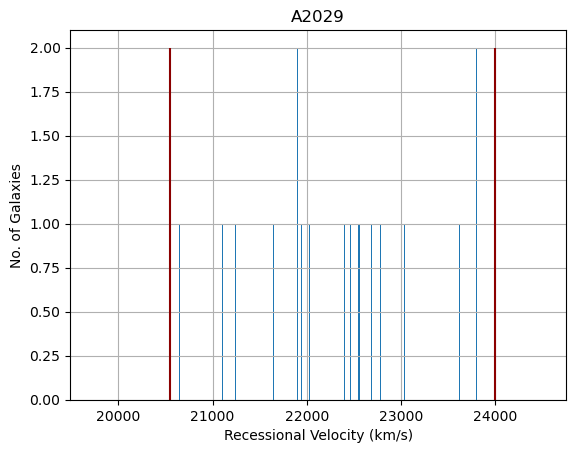

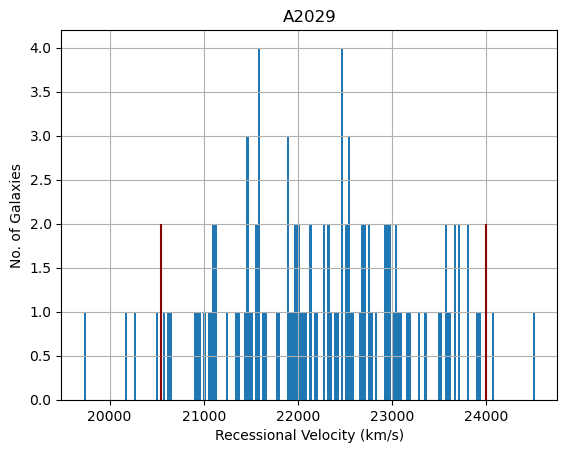

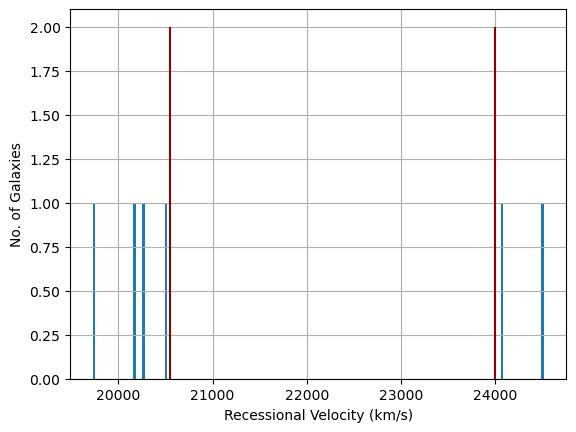

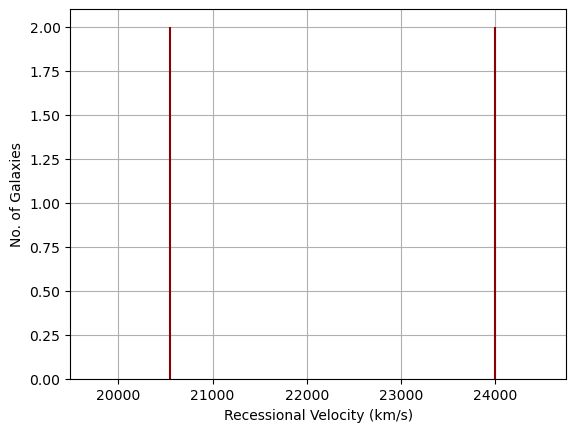

0.004983289841065354


In [129]:
"""
lower_lims = [0.07,0.082,0.046,0.052,0.064,0.0685]
upper_lims = [0.081,0.091,0.058,0.064,0.073,0.08]

# Set up custom query and define which columns we want
customSimbad = Simbad()
customSimbad.add_votable_fields('ra', 'dec', 'mesdistance', 'otype', 'rvz_radvel', 'rvz_redshift')
    
    
# query
ra_A2029 = XCOP_clusters['ra'][5]
dec_A2029 = XCOP_clusters['dec'][5]
radius_A2029 = radii[5] * u.arcmin
gal_df = query(ra_A2029, dec_A2029, radius_A2029) # Get full query again
    
# Zoom in and get array
cluster = gal_df[(gal_df['rvz_redshift']>lower_limit[5])&(gal_df['rvz_redshift']<upper_limit[5])]
cluster_vels = cluster['rvz_radvel'].values
# sky = gal_df # 'Whole sky'
    
#Compute mu and sigma guesses
mu_guess = np.mean(cluster_vels)
sigma_guess = np.std(cluster_vels)
   
nb = 2000 # Number of bins
    
# Compute histogram values (i.e. x and y)
v_hist, bin_edges = np.histogram(cluster_vels, bins=nb)
    
# Compute bin centres
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
lower_lim = lower_lims[5]*3e5 #mu_guess-(2*sigma_guess)
upper_lim = upper_lims[5]*3e5 #mu_guess+(2*sigma_guess)
sky = gal_df[(gal_df['rvz_redshift']>lower_limit[5])&(gal_df['rvz_redshift']<upper_limit[5])]
    
#Plot recessional velocity distribution and gaussian 
sky['rvz_radvel'].hist(bins = nb)
#plt.plot(bin_centers, gauss_func(bin_centers, a, mu, sigma))
plt.vlines(lower_lim, 0, v_hist.max(), color = 'darkred')
plt.vlines(upper_lim, 0, v_hist.max(), color = 'darkred')
plt.xlabel('Recessional Velocity (km/s)')
plt.ylabel('No. of Galaxies')
plt.title('A2029')
plt.show()

#Plot recessional velocity distribution and gaussian 
sky['rvz_radvel'].hist(bins = 200)
#plt.plot(bin_centers, gauss_func(bin_centers, a, mu, sigma))
plt.vlines(lower_lim, 0, v_hist.max(), color = 'darkred')
plt.vlines(upper_lim, 0, v_hist.max(), color = 'darkred')
plt.xlabel('Recessional Velocity (km/s)')
plt.ylabel('No. of Galaxies')
plt.title('A2029')
plt.show()
    
nocluster = sky[(sky['rvz_radvel'] < lower_lim) | (sky['rvz_radvel'] > upper_lim)]
nocluster['rvz_radvel'].hist(bins=200)
plt.vlines(lower_lim, 0, v_hist.max(), color = 'darkred')
plt.vlines(upper_lim, 0, v_hist.max(), color = 'darkred')
plt.xlabel('Recessional Velocity (km/s)')
plt.ylabel('No. of Galaxies')
plt.show()

nocluster = sky[(sky['rvz_radvel'] < lower_lim) | (sky['rvz_radvel'] > upper_lim)]
nocluster['rvz_radvel'].hist(bins=nb)
plt.vlines(lower_lim, 0, v_hist.max(), color = 'darkred')
plt.vlines(upper_lim, 0, v_hist.max(), color = 'darkred')
plt.xlabel('Recessional Velocity (km/s)')
plt.ylabel('No. of Galaxies')
plt.show()
   
left = nocluster[nocluster['rvz_radvel'] < lower_lim]
right = nocluster[nocluster['rvz_radvel'] > upper_lim]

left_vels = left['rvz_radvel'].values
right_vels = right['rvz_radvel'].values
left_hist, bin_edges = np.histogram(left_vels, bins=nb)
right_hist, bin_edges = np.histogram(right_vels, bins=nb)
if len(left_vels)!=0 and len(right_vels)!=0:
    background = (left_hist.sum() + right_hist.sum())/((left_vels.max() - left_vels.min()) + (right_vels.max() - right_vels.min()))
elif len(left_vels)==0 and len(right_vels)!=0:
    background = (left_hist.sum() + right_hist.sum())/(right_vels.max() - right_vels.min())
elif len(left_vels)!=0 and len(right_vels)==0:
    background = (left_hist.sum() + right_hist.sum())/((left_vels.max() - left_vels.min()))
else:
    background = 0
background_rate.append(background)
print(background)
"""